In [4]:
import pandas as pd
import numpy as np
import statsmodels.api as sm
from sklearn.metrics import confusion_matrix, classification_report, roc_curve, auc
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('../data/processed/ufc_r1_clean_2016.csv')

# Definir Variável Resposta (Y) e Matriz de Covariáveis (X)
y = df['y_red_win']
X = df[['diff_sig_landed', 'diff_kd', 'diff_td_success', 
        'diff_ctrl_sec', 'diff_sub_att', 'diff_sig_acc']]

# Adicionar a constante (Intercepto beta_0) exigida pelo statsmodels
X = sm.add_constant(X)

In [5]:
# Ajustar o Modelo de Regressão Logística (Logit)
modelo = sm.Logit(y, X).fit()

print(modelo.summary())

Optimization terminated successfully.
         Current function value: 0.602488
         Iterations 5
                           Logit Regression Results                           
Dep. Variable:              y_red_win   No. Observations:                 4196
Model:                          Logit   Df Residuals:                     4189
Method:                           MLE   Df Model:                            6
Date:                Wed, 18 Nov 2026   Pseudo R-squ.:                  0.1191
Time:                        12:51:45   Log-Likelihood:                -2528.0
converged:                       True   LL-Null:                       -2869.9
Covariance Type:            nonrobust   LLR p-value:                2.032e-144
                      coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------
const               0.2210      0.034      6.521      0.000       0.155       0.287
diff_sig_lande

In [6]:
# Calcular Odds Ratios e os Intervalos de Confiança de 95%
odds_ratios = pd.DataFrame({
    'Odds Ratio (exp(beta))': np.exp(modelo.params),
    'IC 95% Inferior': np.exp(modelo.conf_int()[0]),
    'IC 95% Superior': np.exp(modelo.conf_int()[1]),
    'P-valor': modelo.pvalues
})

print("\n--- Interpretação dos Odds Ratios ---")
display(odds_ratios.round(4))


--- Interpretação dos Odds Ratios ---


,Odds Ratio (exp(beta)),IC 95% Inferior,IC 95% Superior,P-valor
const,1.2474,1.1672,1.3331,0.0000
diff_sig_landed,1.0616,1.0531,1.0702,0.0000
diff_kd,1.0363,0.8436,1.2729,0.7343
diff_td_success,1.1524,1.0734,1.2372,0.0001
diff_ctrl_sec,1.0026,1.0017,1.0034,0.0000
diff_sub_att,1.1711,1.0296,1.3320,0.0162
diff_sig_acc,1.2590,0.8546,1.8548,0.2440


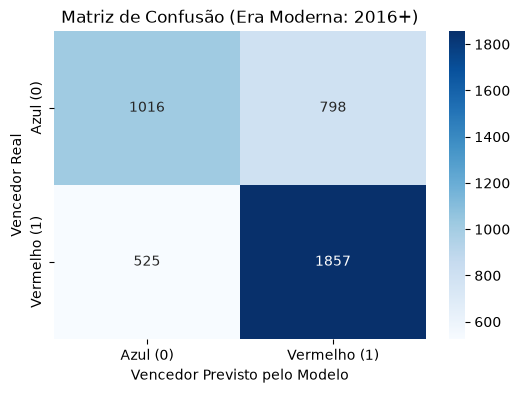

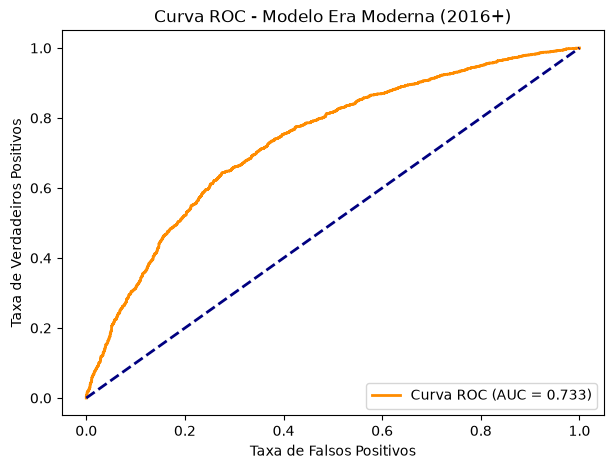

In [8]:
from sklearn.metrics import confusion_matrix, roc_curve, auc
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Gerar probabilidades previstas para o modelo de 2016+
y_prob_2016 = modelo.predict(X)
y_pred_2016 = (y_prob_2016 >= 0.5).astype(int)

# 2. Matriz de Confusão (2016+)
cm_2016 = confusion_matrix(y, y_pred_2016)
plt.figure(figsize=(6,4))
sns.heatmap(cm_2016, annot=True, fmt='d', cmap='Blues', 
            xticklabels=['Azul (0)', 'Vermelho (1)'], 
            yticklabels=['Azul (0)', 'Vermelho (1)'])
plt.ylabel('Vencedor Real')
plt.xlabel('Vencedor Previsto pelo Modelo')
plt.title('Matriz de Confusão (Era Moderna: 2016+)')
plt.show()

# 3. Curva ROC (2016+)
fpr, tpr, thresholds = roc_curve(y, y_prob_2016)
roc_auc_2016 = auc(fpr, tpr)

plt.figure(figsize=(7,5))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'Curva ROC (AUC = {roc_auc_2016:.3f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlabel('Taxa de Falsos Positivos')
plt.ylabel('Taxa de Verdadeiros Positivos')
plt.title('Curva ROC - Modelo Era Moderna (2016+)')
plt.legend(loc="lower right")
plt.show()